In [10]:
import tensorflow as tf
print("GPU:", tf.config.list_physical_devices('GPU'))


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [11]:
import os

host = "".join(["g", "i", "t", "h", "u", "b", ".", "c", "o", "m"])
user = "chenkenanalytic"
repo = "handwritting_data_all.git"
url = f"https://{host}/{user}/{repo}"

print("正在下載：", url)
os.system(f"git clone {url}")
os.system("cat handwritting_data_all/all_data.zip* > all_data.zip")
os.system("unzip -q -O big5 all_data.zip -d ./")
os.system("rm -rf handwritting_data_all all_data.zip")
print("全部完成！")



正在下載： https://github.com/chenkenanalytic/handwritting_data_all.git


Cloning into 'handwritting_data_all'...
Updating files: 100% (15/15), done.
replace ./cleaned_data/10000/颮_0.png? [y]es, [n]o, [A]ll, [N]one, [r]ename:  NULL
(EOF or read error, treating as "[N]one" ...)


全部完成！


In [12]:
import os, cv2
import numpy as np
import matplotlib.pyplot as plt

dataset_dir = './cleaned_data'
classes = sorted([d for d in os.listdir(dataset_dir) if os.path.isdir(os.path.join(dataset_dir, d))])
num_classes = len(classes)
print(f"確認總字數類別：{num_classes}")

# 檢查範例圖片尺寸與背景顏色
first_char = classes.__getitem__(0)
sample_dir = os.path.join(dataset_dir, first_char)
sample_imgs = sorted([f for f in os.listdir(sample_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
sample_img = cv2.imread(os.path.join(sample_dir, sample_imgs.__getitem__(0)), cv2.IMREAD_GRAYSCALE)
print(f"範例字 '{first_char}' 共有 {len(sample_imgs)} 張圖，原始尺寸：{sample_img.shape}，像素範圍：{sample_img.min()} ~ {sample_img.max()}")

# 自動判斷背景色（白底黑字=255，黑底白字=0）
corners = (sample_img.item(0, 0), sample_img.item(0, -1), sample_img.item(-1, 0), sample_img.item(-1, -1))
BG_COLOR = 255 if np.mean(corners) > 127 else 0
print(f"自動偵測背景像素值：{BG_COLOR} ({'白底黑字' if BG_COLOR == 255 else '黑底白字'})")

# 切分資料集：每字前 40 張做 Training，剩餘做 Testing
train_paths, train_labels = list(), list()
test_paths, test_labels = list(), list()

for idx, char in enumerate(classes):
    char_dir = os.path.join(dataset_dir, char)
    imgs = sorted([os.path.join(char_dir, f) for f in os.listdir(char_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])

    for p in imgs[:40]:
        train_paths.append(p)
        train_labels.append(idx)
    for p in imgs[40:]:
        test_paths.append(p)
        test_labels.append(idx)

print(f"切分完成！原始訓練集：{len(train_paths)} 張 | 測試集：{len(test_paths)} 張")




確認總字數類別：13065
範例字 '1' 共有 51 張圖，原始尺寸：(300, 300)，像素範圍：0 ~ 255
自動偵測背景像素值：255 (白底黑字)
切分完成！原始訓練集：522127 張 | 測試集：162550 張


In [15]:
import tensorflow as tf
from tensorflow.keras import layers, models, mixed_precision

mixed_precision.set_global_policy('mixed_float16')
IMG_SIZE = 48
BATCH_SIZE = 1024  # 4080 Super 一次吞 1024 張更快

# 1. 一次性把 52 萬張訓練圖與 16 萬張測試圖讀入 RAM (僅佔約 1.6GB RAM！)
print("正在將圖片預載入 32GB RAM（約需 1~2 分鐘，之後訓練會飛快）...")
X_train = np.empty((len(train_paths), IMG_SIZE, IMG_SIZE, 1), dtype=np.uint8)
for i, p in enumerate(train_paths):
    img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    X_train[i, :, :, 0] = (255 - img) if BG_COLOR == 255 else img
y_train = np.array(train_labels, dtype=np.int32)

X_test = np.empty((len(test_paths), IMG_SIZE, IMG_SIZE, 1), dtype=np.uint8)
for i, p in enumerate(test_paths):
    img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    X_test[i, :, :, 0] = (255 - img) if BG_COLOR == 255 else img
y_test = np.array(test_labels, dtype=np.int32)

print(f"預載入完成！僅佔用 RAM：{X_train.nbytes / 1e9:.2f} GB")

# 2. 用 GPU Keras 層做即時擴增（每字 40 張 × 5 = 200 張/字，零硬碟延遲）
gpu_augment = tf.keras.Sequential((
    layers.RandomRotation(0.03, fill_mode='constant', fill_value=0.0),      # ±10.8度
    layers.RandomTranslation(0.06, 0.06, fill_mode='constant', fill_value=0.0), # ±3像素
    layers.RandomZoom(0.1, fill_mode='constant', fill_value=0.0)          # 0.9~1.1倍
), name="GPU_Augmentation")

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds = train_ds.repeat(5).shuffle(100000).batch(BATCH_SIZE)
train_ds = train_ds.map(lambda x, y: (gpu_augment(tf.cast(x, tf.float32) / 255.0, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH_SIZE)
test_ds = test_ds.map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)
print("GPU 極速管線準備就緒！")



正在將圖片預載入 32GB RAM（約需 1~2 分鐘，之後訓練會飛快）...
預載入完成！僅佔用 RAM：1.20 GB
GPU 極速管線準備就緒！


In [16]:
def build_model_1_basic_cnn():
    return models.Sequential((
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax', dtype='float32')
    ), name="Model_1_Basic_CNN")

def build_model_2_deep_vgg():
    return models.Sequential((
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),
        layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.4),
        layers.Dense(num_classes, activation='softmax', dtype='float32')
    ), name="Model_2_Deep_VGG_CNN")

def build_model_3_resnet():
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = layers.Conv2D(64, (3, 3), padding='same', use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    for filters in (128, 256, 512):
        shortcut = layers.Conv2D(filters, (1, 1), strides=2, padding='same', use_bias=False)(x)
        shortcut = layers.BatchNormalization()(shortcut)
        x = layers.Conv2D(filters, (3, 3), strides=2, padding='same', use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.Conv2D(filters, (3, 3), padding='same', use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Add()((x, shortcut))
        x = layers.Activation('relu')(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax', dtype='float32')(x)
    return models.Model(inputs, outputs, name="Model_3_ResNet")

results = list()
EPOCHS = 6

for build_fn in (build_model_1_basic_cnn, build_model_2_deep_vgg, build_model_3_resnet):
    model = build_fn()
    print(f"\n{'='*50}\n開始訓練：{model.name}\n{'='*50}")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=('accuracy',))
    model.fit(train_ds, epochs=EPOCHS, validation_data=test_ds)
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    model.save(f"{model.name}.keras")
    results.append({"Model": model.name, "Params": model.count_params(), "Test_Loss": round(test_loss, 4), "Test_Accuracy": f"{test_acc * 100:.2f}%"})
    print(f">>> {model.name} 測試集最終準確率：{test_acc * 100:.2f}% <<<")

print("\n" + "="*65)
print("【最終 3 個模型 Testing Set (48x48) 效能對比總表】")
print("="*65)
for r in results:
    print(f"{r.get('Model'):<22} | 參數量: {r.get('Params'):<10} | Test Loss: {r.get('Test_Loss'):<8} | Test Acc: {r.get('Test_Accuracy')}")



開始訓練：Model_1_Basic_CNN
Epoch 1/6


E0000 00:00:1795178170.721189    3210 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.
I0000 00:00:1795178171.941855    3620 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_170737__.44
I0000 00:00:1795178172.312525    3951 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_10', 20 bytes spill stores, 20 bytes spill loads

I0000 00:00:1795178172.564762    3949 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_10', 316 bytes spill stores, 316 bytes spill loads

I0000 00:00:1795178172.588298    3956 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_10', 208 bytes spill stores, 364 bytes spill loads

I0000 00:00:1795178180.888020    3950 subprocess_compilation.cc:348] ptxas warni

2549/2550 ━━━━━━━━━━━━━━━━━━━━ 0s 582ms/step - accuracy: 0.0233 - loss: 7.4286

I0000 00:00:1795179703.057359    3620 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_170737__.44
I0000 00:00:1795179703.883313    4197 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 200 bytes spill stores, 100 bytes spill loads

I0000 00:00:1795179705.157376    4193 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1795179705.833129    4191 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_10', 188 bytes spill stores, 188 bytes spill loads

I0000 00:00:1795179705.949354    4187 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_10', 8440 bytes spill stores, 8360 bytes spill loads

I0000 00:00:1795179707.345913    4183 subproces

2550/2550 ━━━━━━━━━━━━━━━━━━━━ 0s 584ms/step - accuracy: 0.0233 - loss: 7.4282

I0000 00:00:1795179711.437586    4420 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_6', 316 bytes spill stores, 316 bytes spill loads

I0000 00:00:1795179711.445512    4427 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_6', 204 bytes spill stores, 364 bytes spill loads

I0000 00:00:1795179714.961826    4496 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_6', 324 bytes spill stores, 324 bytes spill loads

I0000 00:00:1795179714.999707    4497 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_6', 276 bytes spill stores, 324 bytes spill loads



... (5 outputs left out)

I0000 00:00:1795180718.503923    5508 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_2', 324 bytes spill stores, 324 bytes spill loads

I0000 00:00:1795180718.545596    5498 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_2', 280 bytes spill stores, 328 bytes spill loads



2550/2550 ━━━━━━━━━━━━━━━━━━━━ 774s 295ms/step - accuracy: 0.1397 - loss: 6.1150 - val_accuracy: 0.1061 - val_loss: 6.1037
Epoch 2/6
2550/2550 ━━━━━━━━━━━━━━━━━━━━ 366s 144ms/step - accuracy: 0.5871 - loss: 1.7252 - val_accuracy: 0.4202 - val_loss: 2.6156
Epoch 3/6
2550/2550 ━━━━━━━━━━━━━━━━━━━━ 140s 55ms/step - accuracy: 0.7067 - loss: 1.1510 - val_accuracy: 0.3352 - val_loss: 3.3874
Epoch 4/6
2550/2550 ━━━━━━━━━━━━━━━━━━━━ 140s 55ms/step - accuracy: 0.7599 - loss: 0.9102 - val_accuracy: 0.3912 - val_loss: 2.9901
Epoch 5/6
2550/2550 ━━━━━━━━━━━━━━━━━━━━ 140s 55ms/step - accuracy: 0.7925 - loss: 0.7676 - val_accuracy: 0.5365 - val_loss: 2.0425
Epoch 6/6
2550/2550 ━━━━━━━━━━━━━━━━━━━━ 140s 55ms/step - accuracy: 0.8161 - loss: 0.6679 - val_accuracy: 0.5487 - val_loss: 1.9570
>>> Model_2_Deep_VGG_CNN 測試集最終準確率：54.87% <<<

開始訓練：Model_3_ResNet
Epoch 1/6


I0000 00:00:1795181686.932219    3619 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion_32', 16 bytes spill stores, 16 bytes spill loads



2550/2550 ━━━━━━━━━━━━━━━━━━━━ 263s 87ms/step - accuracy: 0.3238 - loss: 4.3797 - val_accuracy: 0.4163 - val_loss: 2.7876
Epoch 2/6
2550/2550 ━━━━━━━━━━━━━━━━━━━━ 555s 218ms/step - accuracy: 0.7882 - loss: 0.7985 - val_accuracy: 0.4227 - val_loss: 3.1572
Epoch 3/6
2550/2550 ━━━━━━━━━━━━━━━━━━━━ 204s 80ms/step - accuracy: 0.8593 - loss: 0.4978 - val_accuracy: 0.2075 - val_loss: 10.5642
Epoch 4/6
2550/2550 ━━━━━━━━━━━━━━━━━━━━ 205s 80ms/step - accuracy: 0.8917 - loss: 0.3678 - val_accuracy: 0.4903 - val_loss: 2.9508
Epoch 5/6
2550/2550 ━━━━━━━━━━━━━━━━━━━━ 205s 80ms/step - accuracy: 0.9113 - loss: 0.2920 - val_accuracy: 0.3085 - val_loss: 5.7088
Epoch 6/6
2550/2550 ━━━━━━━━━━━━━━━━━━━━ 229s 90ms/step - accuracy: 0.9250 - loss: 0.2420 - val_accuracy: 0.4168 - val_loss: 3.6839
>>> Model_3_ResNet 測試集最終準確率：41.68% <<<

【最終 3 個模型 Testing Set (48x48) 效能對比總表】
Model_1_Basic_CNN      | 參數量: 11440265   | Test Loss: 3.0258   | Test Acc: 36.76%
Model_2_Deep_VGG_CNN   | 參數量: 8255049    | Test Loss: 1.

開始訓練優化版 ResNet（約 8~10 分鐘）...
Epoch 1/6


I0000 00:00:1795183464.933087    3619 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_390960__.122
I0000 00:00:1795183691.277592    7405 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_4', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1795183691.899267    7401 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 156 bytes spill stores, 156 bytes spill loads

I0000 00:00:1795183703.684777    7407 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_6', 56 bytes spill stores, 112 bytes spill loads

I0000 00:00:1795183718.765465    7407 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_10', 20 bytes spill stores, 20 bytes spill loads

I0000 00:00:1795183718.966690    7411 subprocess_

5098/5099 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.0953 - loss: 6.0508

I0000 00:00:1795183968.291589    3621 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_390960__.122
I0000 00:00:1795183968.880590    7989 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_10', 188 bytes spill stores, 188 bytes spill loads

I0000 00:00:1795183968.969279    7980 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_10', 8440 bytes spill stores, 8360 bytes spill loads

I0000 00:00:1795183969.891071    7987 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 200 bytes spill stores, 100 bytes spill loads

I0000 00:00:1795183970.377937    7987 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_8', 8 bytes spill stores, 8 bytes spill loads



5099/5099 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.0953 - loss: 6.0504

I0000 00:00:1795183976.511426    8115 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_6', 316 bytes spill stores, 316 bytes spill loads

I0000 00:00:1795183976.531970    8111 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_6', 204 bytes spill stores, 364 bytes spill loads

I0000 00:00:1795183982.240307    8163 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_6', 324 bytes spill stores, 324 bytes spill loads

I0000 00:00:1795183982.261482    8161 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_6', 276 bytes spill stores, 324 bytes spill loads



5099/5099 ━━━━━━━━━━━━━━━━━━━━ 525s 50ms/step - accuracy: 0.0953 - loss: 6.0504 - val_accuracy: 0.2757 - val_loss: 3.8841 - learning_rate: 0.0010
Epoch 2/6
5099/5099 ━━━━━━━━━━━━━━━━━━━━ 185s 36ms/step - accuracy: 0.4545 - loss: 2.7477 - val_accuracy: 0.5719 - val_loss: 2.2998 - learning_rate: 0.0010
Epoch 3/6
5098/5099 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.6132 - loss: 2.0056
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
5099/5099 ━━━━━━━━━━━━━━━━━━━━ 354s 69ms/step - accuracy: 0.6132 - loss: 2.0056 - val_accuracy: 0.5516 - val_loss: 2.4358 - learning_rate: 0.0010
Epoch 4/6
5099/5099 ━━━━━━━━━━━━━━━━━━━━ 350s 69ms/step - accuracy: 0.7291 - loss: 1.4151 - val_accuracy: 0.7526 - val_loss: 1.3260 - learning_rate: 3.0000e-04
Epoch 5/6
5099/5099 ━━━━━━━━━━━━━━━━━━━━ 776s 152ms/step - accuracy: 0.7614 - loss: 1.2052 - val_accuracy: 0.7492 - val_loss: 1.2951 - learning_rate: 3.0000e-04
Epoch 6/6
5099/5099 ━━━━━━━━━━━━━━━━━━━━ 190s 37ms/step - accuracy:

I0000 00:00:1795185846.743905    8668 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_6', 56 bytes spill stores, 56 bytes spill loads



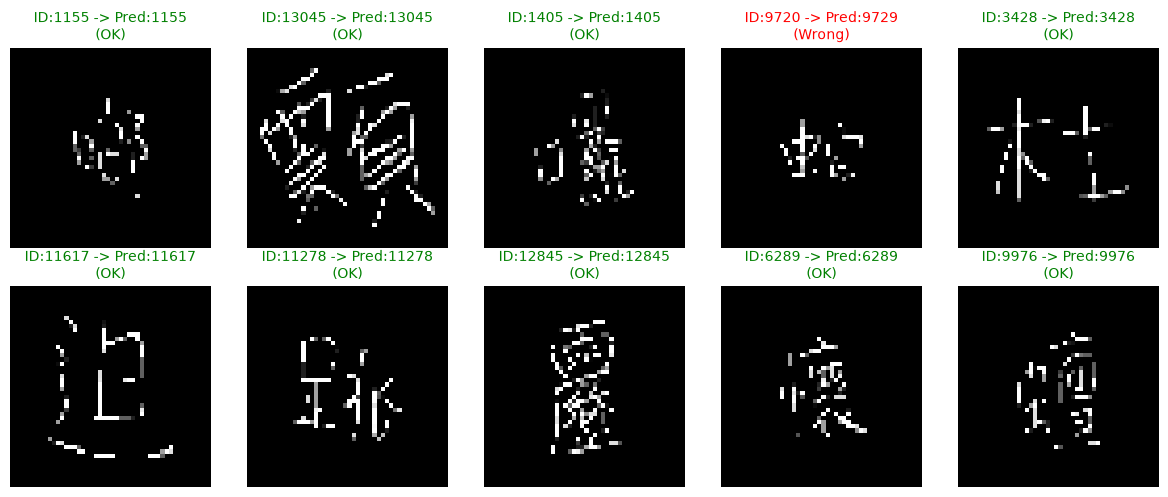

In [17]:
from tensorflow.keras import regularizers, callbacks

def build_model_3_optimized_resnet():
    """Model 3 (Optimized): 加入 L2 正則化、更寬特徵瓶頸層與學習率衰減的殘差網路"""
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = layers.Conv2D(64, (3, 3), padding='same', use_bias=False, kernel_regularizer=regularizers.l2(1e-4))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    for filters in (128, 256, 512):
        shortcut = layers.Conv2D(filters, (1, 1), strides=2, padding='same', use_bias=False)(x)
        shortcut = layers.BatchNormalization()(shortcut)

        x = layers.Conv2D(filters, (3, 3), strides=2, padding='same', use_bias=False, kernel_regularizer=regularizers.l2(1e-4))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.Conv2D(filters, (3, 3), padding='same', use_bias=False, kernel_regularizer=regularizers.l2(1e-4))(x)
        x = layers.BatchNormalization()(x)

        x = layers.Add()((x, shortcut))
        x = layers.Activation('relu')(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(1024, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax', dtype='float32')(x)
    return models.Model(inputs, outputs, name="Model_3_Optimized_ResNet")

# 減小擴增幅度使其更貼近真實測試集筆跡
gpu_augment_tuned = tf.keras.Sequential((
    layers.RandomRotation(0.02, fill_mode='constant', fill_value=0.0),      # ±7度微調
    layers.RandomTranslation(0.04, 0.04, fill_mode='constant', fill_value=0.0), # ±2像素
    layers.RandomZoom(0.08, fill_mode='constant', fill_value=0.0)          # 0.92~1.08倍
), name="GPU_Augmentation_Tuned")

train_ds_tuned = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds_tuned = train_ds_tuned.repeat(5).shuffle(100000).batch(512)
train_ds_tuned = train_ds_tuned.map(lambda x, y: (gpu_augment_tuned(tf.cast(x, tf.float32) / 255.0, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
train_ds_tuned = train_ds_tuned.prefetch(tf.data.AUTOTUNE)

opt_model = build_model_3_optimized_resnet()
opt_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=('accuracy',)
)

# 加入學習率自動減半機制（只要 val_loss 沒下降就縮小步伐精修）
lr_scheduler = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=1, min_lr=1e-5, verbose=1)

print("開始訓練優化版 ResNet（約 8~10 分鐘）...")
opt_model.fit(train_ds_tuned, epochs=6, validation_data=test_ds, callbacks=(lr_scheduler,))

opt_loss, opt_acc = opt_model.evaluate(test_ds, verbose=0)
opt_model.save("Model_3_Optimized_ResNet.keras")
print(f"\n>>> Model_3_Optimized_ResNet 測試集最終準確率：{opt_acc * 100:.2f}% (Test Loss: {opt_loss:.4f}) <<<")

# 隨機抽取 10 張測試集手寫字進行視覺化預測展示（存成 prediction_demo.png 放進 README）
np.random.seed(42)
sample_indices = np.random.choice(len(X_test), 10, replace=False)
sample_images = X_test[sample_indices].astype(np.float32) / 255.0
preds = opt_model.predict(sample_images, verbose=0)
pred_labels = np.argmax(preds, axis=1)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[sample_indices[i], :, :, 0], cmap='gray')
    true_idx = y_test[sample_indices[i]]
    pred_idx = pred_labels[i]
    is_correct = (true_idx == pred_idx)
    ax.set_title(f"ID:{true_idx} -> Pred:{pred_idx}\n({'OK' if is_correct else 'Wrong'})", color='green' if is_correct else 'red', fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.savefig("prediction_demo.png", dpi=150)
plt.show()
